<a href="https://colab.research.google.com/github/Aadityachalak/Image-Captioning-with-Attention/blob/main/image_captioning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Tue Nov 17 13:08:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/MLEE_captioning'
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/MLEE_captioning


In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("adityajn105/flickr8k")
print("Downloaded to:", path)
!ls "{path}"

Using Colab cache for faster access to the 'flickr8k' dataset.
Downloaded to: /kaggle/input/flickr8k
captions.txt  Images


In [ ]:
import pandas as pd

IMG_DIR = os.path.join(path, 'Images')
CAP_FILE = os.path.join(path, 'captions.txt')

n_images = len(os.listdir(IMG_DIR))
df = pd.read_csv(CAP_FILE)

print("Images:", n_images)                      # expect 8091
print("Caption rows:", len(df))                 # expect 40455
print("Unique images in captions:", df['image'].nunique())  # expect 8091
df.head(10)

Images: 8091
Caption rows: 40455
Unique images in captions: 8091


,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...
5,1001773457_577c3a7d70.jpg,A black dog and a spotted dog are fighting
6,1001773457_577c3a7d70.jpg,A black dog and a tri-colored dog playing with...
7,1001773457_577c3a7d70.jpg,A black dog and a white dog with brown spots a...
8,1001773457_577c3a7d70.jpg,Two dogs of different breeds looking at each o...
9,1001773457_577c3a7d70.jpg,Two dogs on pavement moving toward each other .


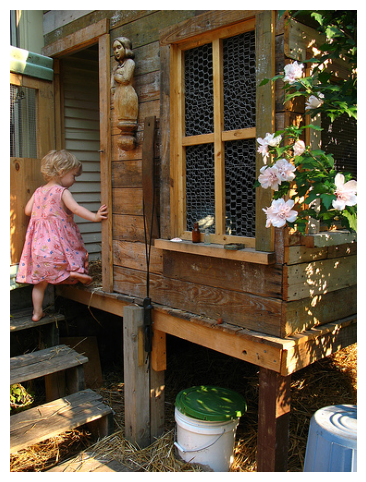

- A child in a pink dress is climbing up a set of stairs in an entry way .
- A girl going into a wooden building .
- A little girl climbing into a wooden playhouse .
- A little girl climbing the stairs to her playhouse .
- A little girl in a pink dress going into a wooden cabin .
Image size: (375, 500)


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

sample = df['image'].iloc[0]
img = Image.open(os.path.join(IMG_DIR, sample))

plt.figure(figsize=(6, 6))
plt.imshow(img); plt.axis('off'); plt.show()

for c in df[df['image'] == sample]['caption']:
    print("-", c)
print("Image size:", img.size)

In [ ]:
!cp "{CAP_FILE}" "{PROJECT_DIR}/captions.txt"
!ls "{PROJECT_DIR}"

captions.txt


In [ ]:
import re, random, pickle, collections
import numpy as np

def clean(caption):
    caption = caption.lower()
    caption = re.sub(r"[^a-z ]", " ", caption)          # keep letters only
    words = [w for w in caption.split() if len(w) > 1 or w == 'a']
    return words

df['tokens'] = df['caption'].apply(clean)

for raw, tok in zip(df['caption'][:3], df['tokens'][:3]):
    print(raw, "\n  ->", tok)

A child in a pink dress is climbing up a set of stairs in an entry way . 
  -> ['a', 'child', 'in', 'a', 'pink', 'dress', 'is', 'climbing', 'up', 'a', 'set', 'of', 'stairs', 'in', 'an', 'entry', 'way']
A girl going into a wooden building . 
  -> ['a', 'girl', 'going', 'into', 'a', 'wooden', 'building']
A little girl climbing into a wooden playhouse . 
  -> ['a', 'little', 'girl', 'climbing', 'into', 'a', 'wooden', 'playhouse']


Average length: 10.8
Longest: 36
95% of captions are <= 18 words
MAX_LEN = 22


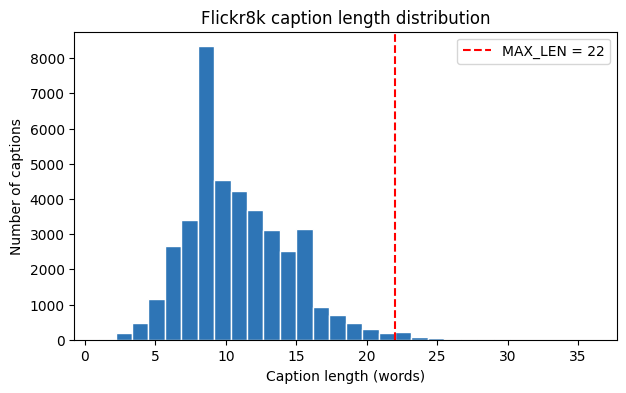

In [ ]:
lengths = df['tokens'].apply(len)
print("Average length:", round(lengths.mean(), 1))
print("Longest:", lengths.max())
print("95% of captions are <=", int(np.percentile(lengths, 95)), "words")

MAX_LEN = int(np.percentile(lengths, 99))     # captions longer than this get cut
print("MAX_LEN =", MAX_LEN)

plt.figure(figsize=(7, 4))
plt.hist(lengths, bins=30, color='#2E75B6', edgecolor='white')
plt.axvline(MAX_LEN, color='red', linestyle='--', label=f'MAX_LEN = {MAX_LEN}')
plt.xlabel('Caption length (words)'); plt.ylabel('Number of captions')
plt.title('Flickr8k caption length distribution'); plt.legend()
plt.savefig(f'{PROJECT_DIR}/fig_caption_lengths.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
images = sorted(df['image'].unique())
random.seed(42)
random.shuffle(images)

test_imgs  = images[:1000]
val_imgs   = images[1000:2000]
train_imgs = images[2000:]
print(f"Train: {len(train_imgs)}  Val: {len(val_imgs)}  Test: {len(test_imgs)}")

Train: 6091  Val: 1000  Test: 1000


In [ ]:
MIN_FREQ = 5
train_set = set(train_imgs)

counter = collections.Counter()
for img, toks in zip(df['image'], df['tokens']):
    if img in train_set:
        counter.update(toks)

words = sorted(w for w, c in counter.items() if c >= MIN_FREQ)
word2idx = {'<pad>': 0, '<start>': 1, '<end>': 2, '<unk>': 3}
for w in words:
    word2idx[w] = len(word2idx)
idx2word = {i: w for w, i in word2idx.items()}

print("Distinct words in train:", len(counter))
print("Vocabulary size (freq >= 5):", len(word2idx))
print("Most common:", counter.most_common(10))

Distinct words in train: 7392
Vocabulary size (freq >= 5): 2568
Most common: [('a', 47407), ('in', 14275), ('the', 13922), ('on', 8070), ('is', 7058), ('and', 6697), ('dog', 6145), ('with', 5806), ('man', 5516), ('of', 5079)]


In [ ]:
SEQ_LEN = MAX_LEN + 2      # +2 for <start> and <end>

def encode(tokens):
    tokens = tokens[:MAX_LEN]
    ids = [word2idx['<start>']] + [word2idx.get(w, word2idx['<unk>']) for w in tokens] + [word2idx['<end>']]
    ids += [word2idx['<pad>']] * (SEQ_LEN - len(ids))
    return ids

img2caps = collections.defaultdict(list)     # image -> 5 encoded captions
img2refs = collections.defaultdict(list)     # image -> 5 cleaned word lists (for BLEU later)
for img, toks in zip(df['image'], df['tokens']):
    img2caps[img].append(encode(toks))
    img2refs[img].append(toks)

ex = train_imgs[0]
print("Words  :", img2refs[ex][0])
print("Numbers:", img2caps[ex][0])
print("Decoded:", [idx2word[i] for i in img2caps[ex][0]])

Words  : ['a', 'busy', 'plaza', 'with', 'several', 'people', 'having', 'conversations']
Numbers: [1, 4, 324, 1640, 2534, 1901, 1570, 1002, 3, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded: ['<start>', 'a', 'busy', 'plaza', 'with', 'several', 'people', 'having', '<unk>', '<end>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']


In [ ]:
data = {
    'word2idx': word2idx, 'idx2word': idx2word,
    'train_imgs': train_imgs, 'val_imgs': val_imgs, 'test_imgs': test_imgs,
    'img2caps': dict(img2caps), 'img2refs': dict(img2refs),
    'MAX_LEN': MAX_LEN, 'SEQ_LEN': SEQ_LEN,
}
with open(f'{PROJECT_DIR}/captions_data.pkl', 'wb') as f:
    pickle.dump(data, f)
print("Saved:", os.listdir(PROJECT_DIR))

Saved: ['captions.txt', 'fig_caption_lengths.png', 'captions_data.pkl']


In [ ]:
import torch, torch.nn as nn
import torchvision
from torchvision import transforms

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using:", device)

weights = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
resnet = torchvision.models.resnet50(weights=weights).to(device).eval()

# Keep everything up to the last conv block; drop avgpool + the 1000-class classifier
encoder = nn.Sequential(*list(resnet.children())[:-2]).to(device).eval()
for p in encoder.parameters():
    p.requires_grad = False          # frozen: we never update these weights

with torch.no_grad():
    out = encoder(torch.zeros(1, 3, 224, 224, device=device))
print("Encoder output shape:", out.shape)     # expect [1, 2048, 7, 7]

Using: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 135MB/s]


Encoder output shape: torch.Size([1, 2048, 7, 7])


In [ ]:
from torch.utils.data import Dataset, DataLoader

all_imgs = train_imgs + val_imgs + test_imgs
img2idx = {img: i for i, img in enumerate(all_imgs)}

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),                       # whole image, no cropping
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],     # ImageNet statistics
                         std=[0.229, 0.224, 0.225]),
])

class ImageFolderList(Dataset):
    def __init__(self, names): self.names = names
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        img = Image.open(os.path.join(IMG_DIR, self.names[i])).convert('RGB')
        return preprocess(img)

loader = DataLoader(ImageFolderList(all_imgs), batch_size=64, num_workers=2)
print("Batches:", len(loader))

Batches: 127


In [ ]:
from tqdm.auto import tqdm

N = len(all_imgs)
spatial = np.zeros((N, 49, 2048), dtype=np.float16)   # ~1.6 GB
pooled  = np.zeros((N, 2048), dtype=np.float32)

i = 0
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    for batch in tqdm(loader):
        fmap = encoder(batch.to(device))                  # [B, 2048, 7, 7]
        fmap = fmap.flatten(2).permute(0, 2, 1)           # [B, 49, 2048]
        b = fmap.shape[0]
        spatial[i:i+b] = fmap.float().cpu().numpy().astype(np.float16)
        pooled[i:i+b]  = fmap.float().mean(dim=1).cpu().numpy()
        i += b

print("Done:", spatial.shape, pooled.shape)

  0%|          | 0/127 [00:00<?, ?it/s]

Done: (8091, 49, 2048) (8091, 2048)


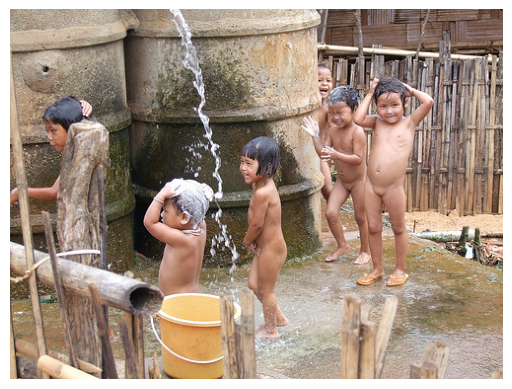

bucket                    0.20
swab                      0.05
chain saw                 0.04
shower cap                0.02
swimming trunks           0.02
Human caption: a group of young naked children showering near large metal containers and a yellow bucket


In [ ]:
k = 5
test_name = all_imgs[k]
with torch.no_grad():
    logits = resnet.fc(torch.tensor(pooled[k:k+1], device=device))
top5 = logits.softmax(-1).topk(5)
cats = weights.meta['categories']

plt.imshow(Image.open(os.path.join(IMG_DIR, test_name))); plt.axis('off'); plt.show()
for p, c in zip(top5.values[0], top5.indices[0]):
    print(f"{cats[c]:25s} {p.item():.2f}")
print("Human caption:", ' '.join(img2refs[test_name][0]))

In [ ]:
np.save(f'{PROJECT_DIR}/feats_spatial.npy', spatial)
np.save(f'{PROJECT_DIR}/feats_pooled.npy', pooled)
with open(f'{PROJECT_DIR}/img2idx.pkl', 'wb') as f:
    pickle.dump(img2idx, f)
!ls -lh "{PROJECT_DIR}"

total 1.6G
-rw------- 1 root root 5.7M Nov 13 11:50 captions_data.pkl
-rw------- 1 root root 3.2M Nov 13 11:36 captions.txt
-rw------- 1 root root  64M Nov 13 12:01 feats_pooled.npy
-rw------- 1 root root 1.6G Nov 13 12:01 feats_spatial.npy
-rw------- 1 root root  91K Nov 13 11:43 fig_caption_lengths.png
-rw------- 1 root root 244K Nov 13 12:01 img2idx.pkl


In [ ]:
import os, json, time, pickle, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from nltk.translate.bleu_score import corpus_bleu
import kagglehub

path = kagglehub.dataset_download("adityajn105/flickr8k")   # instant if still cached
IMG_DIR = os.path.join(path, 'Images')                      # (if you used the kaggle.json route: '/content/flickr8k/Images')

torch.manual_seed(42); np.random.seed(42)
VOCAB = len(word2idx)
PAD, START, END = word2idx['<pad>'], word2idx['<start>'], word2idx['<end>']

pooled_t = torch.tensor(pooled, device=device)        # all image vectors live on the GPU

def build_split(imgs):
    idx, caps = [], []
    for im in imgs:
        for c in img2caps[im]:
            idx.append(img2idx[im]); caps.append(c)
    return torch.tensor(idx, device=device), torch.tensor(caps, device=device)

train_idx, train_caps = build_split(train_imgs)
val_idx,   val_caps   = build_split(val_imgs)
print("Train pairs:", train_caps.shape, " Val pairs:", val_caps.shape)

Using Colab cache for faster access to the 'flickr8k' dataset.
Train pairs: torch.Size([30455, 24])  Val pairs: torch.Size([5000, 24])


In [ ]:
def ids_to_words(ids):
    words = []
    for i in ids:
        w = idx2word[int(i)]
        if w == '<end>': break
        if w not in ('<start>', '<pad>'): words.append(w)
    return words

@torch.no_grad()
def evaluate_bleu(model, feats, imgs, bs=250, **gen_kwargs):
    model.eval(); hyps, refs = [], []
    for s in range(0, len(imgs), bs):
        chunk = imgs[s:s+bs]
        out = model.generate(feats[[img2idx[i] for i in chunk]].float(), **gen_kwargs)
        ids = out[0] if isinstance(out, tuple) else out
        for im, seq in zip(chunk, ids):
            hyps.append(ids_to_words(seq)); refs.append(img2refs[im])
    W = {1: (1,0,0,0), 2: (.5,.5,0,0), 3: (1/3,1/3,1/3,0), 4: (.25,.25,.25,.25)}
    return {f'BLEU-{n}': corpus_bleu(refs, hyps, weights=w) for n, w in W.items()}, hyps

def train_model(model, feats, name, epochs=15, lr=4e-4, batch_size=64, patience=3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {'train_loss': [], 'val_loss': [], 'val_bleu4': []}
    best, bad, n = -1.0, 0, len(train_idx)
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); tot = 0.0
        perm = torch.randperm(n, device=device)
        for s in range(0, n, batch_size):
            b = perm[s:s+batch_size]
            loss = model.loss(feats[train_idx[b]].float(), train_caps[b])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            vl = sum(model.loss(feats[val_idx[s:s+500]].float(), val_caps[s:s+500]).item() * len(val_idx[s:s+500])
                     for s in range(0, len(val_idx), 500)) / len(val_idx)
        bleu4 = evaluate_bleu(model, feats, val_imgs)[0]['BLEU-4']
        hist['train_loss'].append(tot / n); hist['val_loss'].append(vl); hist['val_bleu4'].append(bleu4)
        mark = ''
        if bleu4 > best:
            best, bad = bleu4, 0
            torch.save(model.state_dict(), f'{PROJECT_DIR}/{name}_best.pt'); mark = '  <- best, saved'
        else:
            bad += 1
        print(f"Epoch {ep:2d} | train loss {tot/n:.3f} | val loss {vl:.3f} | val BLEU-4 {bleu4:.4f} | {time.time()-t0:.0f}s{mark}")
        if bad >= patience:
            print("Early stopping: no improvement for", patience, "epochs"); break
    json.dump(hist, open(f'{PROJECT_DIR}/{name}_history.json', 'w'))
    model.load_state_dict(torch.load(f'{PROJECT_DIR}/{name}_best.pt'))
    print(f"Best val BLEU-4: {best:.4f}")
    return hist

In [ ]:
class BaselineCaptioner(nn.Module):
    def __init__(self, vocab_size, feat_dim=2048, embed_dim=256, hidden_dim=512, dropout=0.5):
        super().__init__()
        self.embed  = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)   # word ID -> 256-d vector
        self.init_h = nn.Linear(feat_dim, hidden_dim)                        # image -> starting memory
        self.init_c = nn.Linear(feat_dim, hidden_dim)
        self.lstm   = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.drop   = nn.Dropout(dropout)
        self.fc     = nn.Linear(hidden_dim, vocab_size)                      # memory -> score for every word

    def init_state(self, f):
        f = self.drop(f)
        return torch.tanh(self.init_h(f)).unsqueeze(0), torch.tanh(self.init_c(f)).unsqueeze(0)

    def forward(self, f, caps_in):
        h, c = self.init_state(f)
        out, _ = self.lstm(self.drop(self.embed(caps_in)), (h, c))
        return self.fc(self.drop(out))

    def loss(self, f, caps):
        logits = self(f, caps[:, :-1])                       # input:  <start> a dog runs
        return F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                               caps[:, 1:].reshape(-1),      # target: a dog runs <end>
                               ignore_index=PAD)             # don't grade the padding

    @torch.no_grad()
    def generate(self, f, max_len=None):                     # greedy: pick the top word each step
        h, c = self.init_state(f)
        word = torch.full((f.size(0), 1), START, device=f.device)
        out = []
        for _ in range(max_len or SEQ_LEN - 1):
            o, (h, c) = self.lstm(self.embed(word), (h, c))
            word = self.fc(o).argmax(-1)
            out.append(word)
        return torch.cat(out, 1)

In [ ]:
baseline = BaselineCaptioner(VOCAB).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in baseline.parameters())/1e6:.2f} M")
hist_base = train_model(baseline, pooled_t, 'baseline', epochs=15)

Trainable parameters: 5.65 M
Epoch  1 | train loss 4.331 | val loss 3.610 | val BLEU-4 0.1108 | 9s  <- best, saved
Epoch  2 | train loss 3.555 | val loss 3.253 | val BLEU-4 0.1193 | 7s  <- best, saved
Epoch  3 | train loss 3.280 | val loss 3.071 | val BLEU-4 0.1352 | 8s  <- best, saved
Epoch  4 | train loss 3.109 | val loss 2.962 | val BLEU-4 0.1588 | 7s  <- best, saved
Epoch  5 | train loss 2.989 | val loss 2.886 | val BLEU-4 0.1552 | 7s
Epoch  6 | train loss 2.896 | val loss 2.828 | val BLEU-4 0.1636 | 7s  <- best, saved
Epoch  7 | train loss 2.820 | val loss 2.791 | val BLEU-4 0.1808 | 7s  <- best, saved
Epoch  8 | train loss 2.760 | val loss 2.762 | val BLEU-4 0.1828 | 7s  <- best, saved
Epoch  9 | train loss 2.704 | val loss 2.745 | val BLEU-4 0.1831 | 7s  <- best, saved
Epoch 10 | train loss 2.654 | val loss 2.718 | val BLEU-4 0.1827 | 7s
Epoch 11 | train loss 2.613 | val loss 2.699 | val BLEU-4 0.1875 | 7s  <- best, saved
Epoch 12 | train loss 2.575 | val loss 2.693 | val BLEU-4

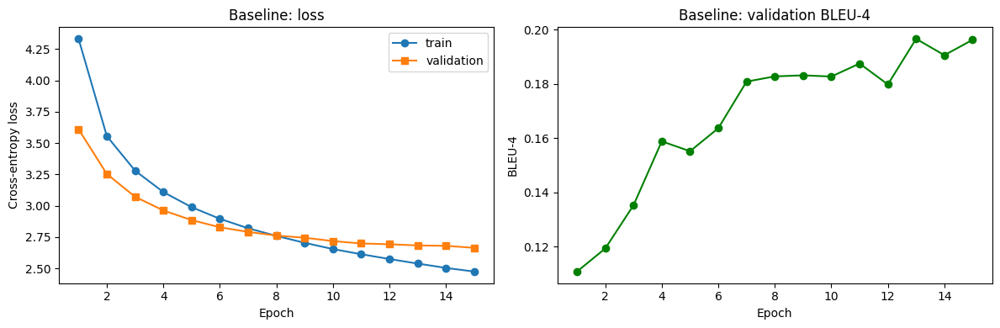

In [ ]:
ep = range(1, len(hist_base['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, hist_base['train_loss'], 'o-', label='train'); ax[0].plot(ep, hist_base['val_loss'], 's-', label='validation')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Cross-entropy loss'); ax[0].set_title('Baseline: loss'); ax[0].legend()
ax[1].plot(ep, hist_base['val_bleu4'], 'o-', color='green')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('BLEU-4'); ax[1].set_title('Baseline: validation BLEU-4')
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/fig_curves_baseline.png', dpi=300); plt.show()

{'BLEU-1': 0.5962, 'BLEU-2': 0.4203, 'BLEU-3': 0.2867, 'BLEU-4': 0.1966}


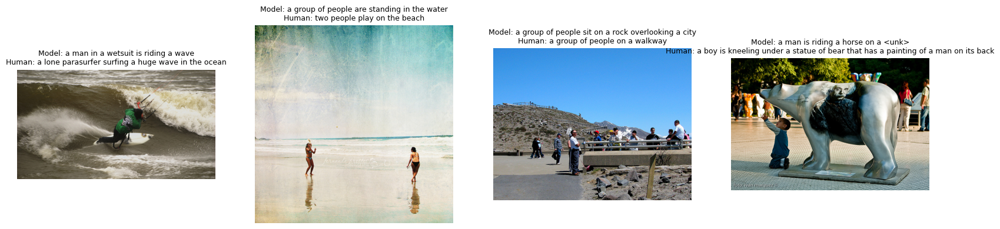

In [ ]:
scores, hyps = evaluate_bleu(baseline, pooled_t, val_imgs)
print({k: round(v, 4) for k, v in scores.items()})

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, k in zip(axes, [0, 10, 20, 30]):
    im = val_imgs[k]
    ax.imshow(Image.open(os.path.join(IMG_DIR, im))); ax.axis('off')
    ax.set_title("Model: " + ' '.join(hyps[k]) + "\nHuman: " + ' '.join(img2refs[im][0]), fontsize=9)
plt.show()

In [ ]:
spatial_t = torch.from_numpy(spatial).to(device)      # [8091, 49, 2048], float16, ~1.6 GB of GPU memory
print(spatial_t.shape, spatial_t.dtype)
print(f"GPU memory used: {torch.cuda.memory_allocated()/1e9:.1f} GB")

torch.Size([8091, 49, 2048]) torch.float16
GPU memory used: 1.7 GB


In [ ]:
class Attention(nn.Module):
    def __init__(self, feat_dim=2048, hidden_dim=512, att_dim=512):
        super().__init__()
        self.feat_proj = nn.Linear(feat_dim, att_dim)     # W_v
        self.hid_proj  = nn.Linear(hidden_dim, att_dim)   # W_h
        self.score     = nn.Linear(att_dim, 1)            # w

    def forward(self, V, V_proj, h):
        e = self.score(torch.tanh(V_proj + self.hid_proj(h).unsqueeze(1))).squeeze(2)   # [B, 49]
        alpha = e.softmax(dim=1)                                                        # weights sum to 1
        context = (alpha.unsqueeze(2) * V).sum(dim=1)                                   # [B, 2048]
        return context, alpha


class AttentionCaptioner(nn.Module):
    def __init__(self, vocab_size, feat_dim=2048, embed_dim=256, hidden_dim=512,
                 att_dim=512, dropout=0.5, lam=1.0):
        super().__init__()
        self.embed  = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.att    = Attention(feat_dim, hidden_dim, att_dim)
        self.init_h = nn.Linear(feat_dim, hidden_dim)     # same initialisation idea as the baseline
        self.init_c = nn.Linear(feat_dim, hidden_dim)
        self.f_beta = nn.Linear(hidden_dim, feat_dim)     # the gate β
        self.lstm   = nn.LSTMCell(embed_dim + feat_dim, hidden_dim)
        self.drop   = nn.Dropout(dropout)
        self.fc     = nn.Linear(hidden_dim, vocab_size)
        self.lam    = lam

    def init_state(self, V):
        m = self.drop(V.mean(dim=1))                      # mean of 49 regions = the baseline's pooled vector
        return torch.tanh(self.init_h(m)), torch.tanh(self.init_c(m))

    def step(self, V, V_proj, word, h, c):                # writes ONE word
        context, alpha = self.att(V, V_proj, h)
        context = torch.sigmoid(self.f_beta(h)) * context
        h, c = self.lstm(torch.cat([self.drop(self.embed(word)), context], dim=1), (h, c))
        return self.fc(self.drop(h)), h, c, alpha

    def forward(self, V, caps_in):
        h, c = self.init_state(V)
        V_proj = self.att.feat_proj(V)                    # computed once, reused for every word
        logits, alphas = [], []
        for t in range(caps_in.size(1)):
            lg, h, c, a = self.step(V, V_proj, caps_in[:, t], h, c)
            logits.append(lg); alphas.append(a)
        return torch.stack(logits, 1), torch.stack(alphas, 1)     # [B,T,vocab], [B,T,49]

    def loss(self, V, caps):
        logits, alphas = self(V, caps[:, :-1])
        targets = caps[:, 1:]
        ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1), ignore_index=PAD)
        mask = (targets != PAD).float().unsqueeze(2)              # ignore attention at padding steps
        reg = ((1.0 - (alphas * mask).sum(dim=1)) ** 2).mean()
        return ce + self.lam * reg

    @torch.no_grad()
    def generate(self, V, max_len=None):
        h, c = self.init_state(V)
        V_proj = self.att.feat_proj(V)
        word = torch.full((V.size(0),), START, device=V.device)
        ids, alphas = [], []
        for _ in range(max_len or SEQ_LEN - 1):
            lg, h, c, a = self.step(V, V_proj, word, h, c)
            word = lg.argmax(-1)
            ids.append(word); alphas.append(a)
        return torch.stack(ids, 1), torch.stack(alphas, 1)        # words + where it looked

In [ ]:
att_model = AttentionCaptioner(VOCAB).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in att_model.parameters())/1e6:.2f} M")

V = spatial_t[train_idx[:4]].float()
logits, alphas = att_model(V, train_caps[:4, :-1])
print("logits:", logits.shape, " alphas:", alphas.shape)
print("each α sums to 1?", torch.allclose(alphas.sum(-1), torch.ones_like(alphas.sum(-1)), atol=1e-4))
print("initial loss:", round(att_model.loss(V, train_caps[:4]).item(), 2), "(expect ≈ ln(vocab) ≈", round(np.log(VOCAB), 1), "+ a bit)")

Trainable parameters: 12.21 M
logits: torch.Size([4, 23, 2568])  alphas: torch.Size([4, 23, 49])
each α sums to 1? True
initial loss: 8.41 (expect ≈ ln(vocab) ≈ 7.9 + a bit)


In [ ]:
torch.manual_seed(42)
att_model = AttentionCaptioner(VOCAB).to(device)
hist_att = train_model(att_model, spatial_t, 'attention', epochs=15)

Epoch  1 | train loss 4.831 | val loss 4.120 | val BLEU-4 0.1299 | 39s  <- best, saved
Epoch  2 | train loss 4.029 | val loss 3.767 | val BLEU-4 0.1509 | 38s  <- best, saved
Epoch  3 | train loss 3.725 | val loss 3.594 | val BLEU-4 0.1729 | 38s  <- best, saved
Epoch  4 | train loss 3.524 | val loss 3.498 | val BLEU-4 0.1871 | 38s  <- best, saved
Epoch  5 | train loss 3.371 | val loss 3.441 | val BLEU-4 0.1989 | 39s  <- best, saved
Epoch  6 | train loss 3.247 | val loss 3.408 | val BLEU-4 0.1996 | 40s  <- best, saved
Epoch  7 | train loss 3.140 | val loss 3.378 | val BLEU-4 0.1995 | 38s
Epoch  8 | train loss 3.047 | val loss 3.371 | val BLEU-4 0.2060 | 38s  <- best, saved
Epoch  9 | train loss 2.963 | val loss 3.363 | val BLEU-4 0.1980 | 38s
Epoch 10 | train loss 2.888 | val loss 3.373 | val BLEU-4 0.2044 | 39s
Epoch 11 | train loss 2.818 | val loss 3.368 | val BLEU-4 0.2087 | 38s  <- best, saved
Epoch 12 | train loss 2.756 | val loss 3.369 | val BLEU-4 0.2072 | 38s
Epoch 13 | train los

In [ ]:
scores_att, hyps_att = evaluate_bleu(att_model, spatial_t, val_imgs)
print("Attention val:", {k: round(v, 4) for k, v in scores_att.items()})
print("Baseline  val:", {k: round(v, 4) for k, v in evaluate_bleu(baseline, pooled_t, val_imgs)[0].items()})

ids, al = att_model.generate(spatial_t[[img2idx[i] for i in val_imgs[:200]]].float())
print(f"\nAverage peak attention weight per word: {al.max(-1).values.mean():.3f}  (uniform would be {1/49:.3f})")

Attention val: {'BLEU-1': 0.6143, 'BLEU-2': 0.4387, 'BLEU-3': 0.302, 'BLEU-4': 0.2087}
Baseline  val: {'BLEU-1': 0.5962, 'BLEU-2': 0.4203, 'BLEU-3': 0.2867, 'BLEU-4': 0.1966}

Average peak attention weight per word: 0.091  (uniform would be 0.020)


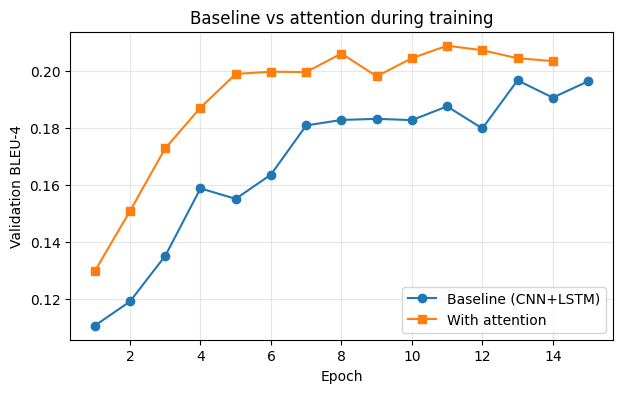


Human    : a lone parasurfer surfing a huge wave in the ocean
Baseline : a man in a wetsuit is riding a wave
Attention: a person in a wetsuit is riding a wave

Human    : two people play on the beach
Baseline : a group of people are standing in the water
Attention: two children are playing in the water

Human    : a group of people on a walkway
Baseline : a group of people sit on a rock overlooking a city
Attention: a group of people are sitting on a stone ledge overlooking a lake

Human    : a boy is kneeling under a statue of bear that has a painting of a man on its back
Baseline : a man is riding a horse on a <unk>
Attention: a dog is standing on a dock in the air


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(hist_base['val_bleu4'])+1), hist_base['val_bleu4'], 'o-', label='Baseline (CNN+LSTM)')
plt.plot(range(1, len(hist_att['val_bleu4'])+1),  hist_att['val_bleu4'],  's-', label='With attention')
plt.xlabel('Epoch'); plt.ylabel('Validation BLEU-4'); plt.title('Baseline vs attention during training')
plt.legend(); plt.grid(alpha=.3)
plt.savefig(f'{PROJECT_DIR}/fig_bleu_curves.png', dpi=300, bbox_inches='tight'); plt.show()

for k in [0, 10, 20, 30]:
    print(f"\nHuman    : {' '.join(img2refs[val_imgs[k]][0])}")
    print(f"Baseline : {' '.join(hyps[k])}")
    print(f"Attention: {' '.join(hyps_att[k])}")

In [ ]:
@torch.no_grad()
def beam_search(model, feat, k=3, max_len=None, len_pen=0.7):
    model.eval()
    is_att = isinstance(model, AttentionCaptioner)
    max_len = max_len or SEQ_LEN - 1
    f = feat.unsqueeze(0).float()                         # one image
    h, c = model.init_state(f)
    Vp = model.att.feat_proj(f) if is_att else None
    seqs   = torch.empty(1, 0, dtype=torch.long, device=f.device)   # partial captions
    scores = torch.zeros(1, device=f.device)                        # their log-prob totals
    alph   = torch.empty(1, 0, 49, device=f.device)                 # attention history
    done = []                                                       # finished captions

    for t in range(max_len):
        n = seqs.size(0)
        words = torch.full((n,), START, device=f.device) if t == 0 else seqs[:, -1]
        if is_att:
            lg, h, c, a = model.step(f.expand(n, -1, -1), Vp.expand(n, -1, -1), words, h, c)
        else:
            o, (h, c) = model.lstm(model.embed(words).unsqueeze(1), (h, c))
            lg = model.fc(o.squeeze(1))

        cand = (scores.unsqueeze(1) + lg.log_softmax(-1)).view(-1)  # every beam x every next word
        top_s, top_i = cand.topk(k - len(done))
        b, w = top_i // VOCAB, top_i % VOCAB                        # which beam, which word
        seqs, scores = torch.cat([seqs[b], w.unsqueeze(1)], 1), top_s
        h, c = (h[b], c[b]) if is_att else (h[:, b], c[:, b])
        if is_att: alph = torch.cat([alph[b], a[b].unsqueeze(1)], 1)

        ended = (w == END)
        for j in ended.nonzero().flatten().tolist():                # captions that just said <end>
            done.append((scores[j].item() / seqs.size(1) ** len_pen,
                         seqs[j, :-1].tolist(), alph[j, :-1] if is_att else None))
        keep = ~ended
        seqs, scores = seqs[keep], scores[keep]
        h, c = (h[keep], c[keep]) if is_att else (h[:, keep], c[:, keep])
        if is_att: alph = alph[keep]
        if seqs.size(0) == 0: break

    for j in range(seqs.size(0)):                                   # hit max length without <end>
        done.append((scores[j].item() / max(seqs.size(1), 1) ** len_pen,
                     seqs[j].tolist(), alph[j] if is_att else None))
    best = max(done, key=lambda x: x[0])
    return best[1], best[2]                                         # word IDs, attention maps

def evaluate_beam(model, feats, imgs, k=3):
    hyps, refs, alphas = [], [], {}
    for im in tqdm(imgs, leave=False):
        toks, al = beam_search(model, feats[img2idx[im]], k=k)
        hyps.append(ids_to_words(toks)); refs.append(img2refs[im]); alphas[im] = al
    W = {1: (1,0,0,0), 2: (.5,.5,0,0), 3: (1/3,1/3,1/3,0), 4: (.25,.25,.25,.25)}
    return {f'BLEU-{n}': corpus_bleu(refs, hyps, weights=w) for n, w in W.items()}, hyps, alphas

In [ ]:
g = evaluate_bleu(att_model, spatial_t, val_imgs[:200])[0]['BLEU-4']
b1 = evaluate_beam(att_model, spatial_t, val_imgs[:200], k=1)[0]['BLEU-4']
print(f"Greedy BLEU-4: {g:.4f}   Beam k=1 BLEU-4: {b1:.4f}   (should be equal or nearly equal)")

  0%|          | 0/200 [00:00<?, ?it/s]

Greedy BLEU-4: 0.2084   Beam k=1 BLEU-4: 0.2084   (should be equal or nearly equal)


In [ ]:
results_val = {}
for name, model, feats in [('Baseline', baseline, pooled_t), ('Attention', att_model, spatial_t)]:
    for k in [1, 3, 5]:
        s, h, _ = evaluate_beam(model, feats, val_imgs, k=k)
        results_val[f'{name} k={k}'] = s
        avg_len = np.mean([len(x) for x in h])
        print(f"{name:9s} k={k} | " + " ".join(f"{m} {v:.4f}" for m, v in s.items()) + f" | avg length {avg_len:.1f}")

json.dump(results_val, open(f'{PROJECT_DIR}/results_val_beam.json', 'w'), indent=1)

  0%|          | 0/1000 [00:00<?, ?it/s]

Baseline  k=1 | BLEU-1 0.5962 BLEU-2 0.4203 BLEU-3 0.2867 BLEU-4 0.1966 | avg length 10.7


  0%|          | 0/1000 [00:00<?, ?it/s]

Baseline  k=3 | BLEU-1 0.6169 BLEU-2 0.4371 BLEU-3 0.3016 BLEU-4 0.2074 | avg length 10.4


  0%|          | 0/1000 [00:00<?, ?it/s]

Baseline  k=5 | BLEU-1 0.6220 BLEU-2 0.4425 BLEU-3 0.3054 BLEU-4 0.2096 | avg length 10.1


... (2 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

Attention k=3 | BLEU-1 0.6440 BLEU-2 0.4672 BLEU-3 0.3300 BLEU-4 0.2299 | avg length 10.1


  0%|          | 0/1000 [00:00<?, ?it/s]

Attention k=5 | BLEU-1 0.6476 BLEU-2 0.4730 BLEU-3 0.3373 BLEU-4 0.2369 | avg length 9.9


In [ ]:
for im in val_imgs[:5]:
    g_ids = att_model.generate(spatial_t[[img2idx[im]]].float())[0][0]
    b_ids, _ = beam_search(att_model, spatial_t[img2idx[im]], k=3)
    print(f"Human : {' '.join(img2refs[im][0])}")
    print(f"Greedy: {' '.join(ids_to_words(g_ids))}")
    print(f"Beam 3: {' '.join(ids_to_words(b_ids))}\n")

Human : a lone parasurfer surfing a huge wave in the ocean
Greedy: a person in a wetsuit is riding a wave
Beam 3: a person in a wetsuit is riding a wave

Human : a brown dog is lowering his head near a smaller white dog outdoors
Greedy: two dogs are playing in the grass
Beam 3: two dogs are playing in the grass

Human : a brown dog is jumping up at another dog in front of the man in jeans
Greedy: a brown dog is standing in front of a large brown dog
Beam 3: a brown dog is playing with a brown dog

Human : a brown dog jumps over a chain
Greedy: a man is climbing a rope
Beam 3: a brown horse is climbing on a rope swing

Human : a lone surfboarder surfing a wave riding a white surfboard
Greedy: a surfer is riding a wave on a surfboard
Beam 3: a surfer rides a wave



In [ ]:
import pandas as pd
BEST_K = 5          # ← set this to the k that won on validation in Cell 32

final, test_hyps = {}, {}
for name, model, feats in [('Baseline', baseline, pooled_t), ('Attention', att_model, spatial_t)]:
    s, h = evaluate_bleu(model, feats, test_imgs)
    final[f'{name} (greedy)'], test_hyps[f'{name} (greedy)'] = s, h
    s, h, al = evaluate_beam(model, feats, test_imgs, k=BEST_K)
    final[f'{name} (beam {BEST_K})'], test_hyps[f'{name} (beam {BEST_K})'] = s, h
    if name == 'Attention':
        test_alphas = al

results = (pd.DataFrame(final).T * 100).round(2)     # BLEU ×100, the convention used in papers
display(results)

results.to_csv(f'{PROJECT_DIR}/results_test.csv')
json.dump(test_hyps, open(f'{PROJECT_DIR}/test_captions.json', 'w'))
torch.save(test_alphas, f'{PROJECT_DIR}/test_alphas.pt')            # needed in Step 8

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
Baseline (greedy),59.75,41.90,28.09,18.72
Baseline (beam 5),61.83,44.30,31.00,21.74
Attention (greedy),62.21,45.03,31.46,21.59
Attention (beam 5),65.29,48.09,34.46,24.36


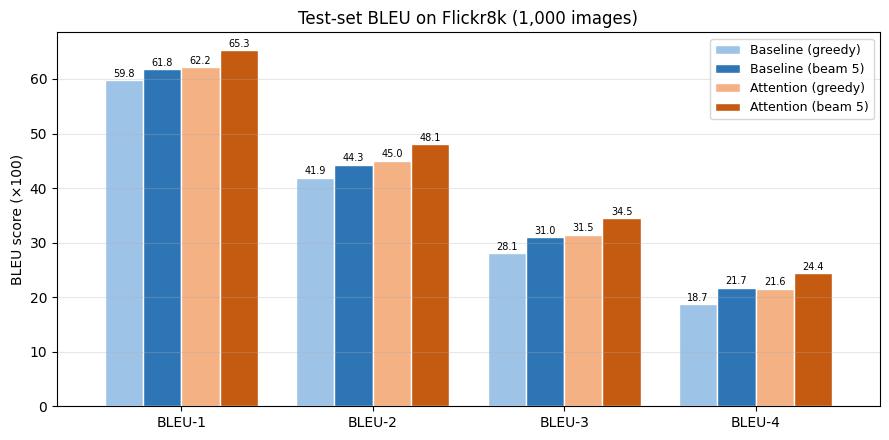

In [ ]:
ax = results.T.plot(kind='bar', figsize=(9, 4.5), width=0.8,
                    color=['#9DC3E6', '#2E75B6', '#F4B183', '#C55A11'], edgecolor='white')
ax.set_ylabel('BLEU score (×100)'); ax.set_xlabel('')
ax.set_title('Test-set BLEU on Flickr8k (1,000 images)')
ax.set_xticklabels(results.columns, rotation=0); ax.grid(axis='y', alpha=.3)
ax.legend(fontsize=9)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.1f', fontsize=7, padding=1)
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/fig_result1.png', dpi=300); plt.show()

In [ ]:
train_caps_set = {' '.join(t) for im in train_imgs for t in img2refs[im]}

rows = {}
for name, hyps_ in test_hyps.items():
    sents = [' '.join(h) for h in hyps_]
    rows[name] = {
        'Avg length (words)': np.mean([len(h) for h in hyps_]),
        'Unique words used': len({w for h in hyps_ for w in h}),
        'Distinct captions (%)': 100 * len(set(sents)) / len(sents),
        'Novel captions (%)': 100 * np.mean([s not in train_caps_set for s in sents]),
    }
diversity = pd.DataFrame(rows).T.round(1)
display(diversity)
diversity.to_csv(f'{PROJECT_DIR}/results_diversity.csv')

print("\nMost repeated baseline captions:")
print(pd.Series([' '.join(h) for h in test_hyps[f'Baseline (beam {BEST_K})']]).value_counts().head(5))

,Avg length (words),Unique words used,Distinct captions (%),Novel captions (%)
Baseline (greedy),10.6,275.0,74.9,91.3
Baseline (beam 5),10.1,273.0,65.5,89.3
Attention (greedy),10.4,374.0,93.4,94.5
Attention (beam 5),9.9,374.0,89.5,93.5



Most repeated baseline captions:
a brown dog is running through the grass                 15
a group of people are standing in front of a building    15
a man in a red jacket is skiing down a snowy hill        13
two dogs run through the grass                           11
a black and white dog is running through the grass       10
Name: count, dtype: int64


In [ ]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
refs_h, hyps_h = [], []
for im in test_imgs:
    caps5 = img2refs[im]
    for i in range(5):
        hyps_h.append(caps5[i]); refs_h.append(caps5[:i] + caps5[i+1:])
human_b4 = 100 * corpus_bleu(refs_h, hyps_h, weights=(.25,.25,.25,.25))
print(f"Human BLEU-4 (leave-one-out, 4 references): {human_b4:.1f}")

Human BLEU-4 (leave-one-out, 4 references): 21.8


In [ ]:
sm = SmoothingFunction().method1
hb, ha = test_hyps[f'Baseline (beam {BEST_K})'], test_hyps[f'Attention (beam {BEST_K})']
per_img = pd.DataFrame({
    'image': test_imgs,
    'baseline': [sentence_bleu(img2refs[im], h, smoothing_function=sm) for im, h in zip(test_imgs, hb)],
    'attention': [sentence_bleu(img2refs[im], h, smoothing_function=sm) for im, h in zip(test_imgs, ha)],
    'base_cap': [' '.join(h) for h in hb], 'att_cap': [' '.join(h) for h in ha],
})
per_img['diff'] = per_img['attention'] - per_img['baseline']
print(f"Attention better: {(per_img['diff'] > 0).mean()*100:.0f}%   "
      f"Same: {(per_img['diff'] == 0).mean()*100:.0f}%   Baseline better: {(per_img['diff'] < 0).mean()*100:.0f}%")

per_img.to_csv(f'{PROJECT_DIR}/per_image_bleu.csv', index=False)
pd.set_option('display.max_colwidth', 80)
print("\nBiggest attention wins:");  display(per_img.nlargest(5, 'diff')[['image', 'base_cap', 'att_cap']])
print("Biggest attention losses:"); display(per_img.nsmallest(5, 'diff')[['image', 'base_cap', 'att_cap']])

Attention better: 52%   Same: 9%   Baseline better: 40%

Biggest attention wins:


,image,base_cap,att_cap
745,3066338314_2c3fb731d1.jpg,a man and a woman sit at a table,a man sits at a table
654,2735558076_0d7bbc18fc.jpg,a man in a red shirt is sitting on a bench,a group of people sitting on the street
973,2616508003_fa5ca5780d.jpg,a man on a motorcycle,a person on a motorcycle
866,3446586125_cafa0bfd67.jpg,a brown dog is running through the grass,a brown dog is running with a tennis ball in its mouth
585,368954110_821ccf005c.jpg,a little girl in a pink shirt is running down a dirt road,two children are sitting on the grass


Biggest attention losses:


,image,base_cap,att_cap
535,526661994_21838fc72c.jpg,a dog runs through the grass,a black and brown dog is running in the grass
458,3210457502_c6030ce567.jpg,a white bird is flying over the water,a large white bird flies over the water
46,2326730558_75c20e5033.jpg,two dogs play in the snow,two dogs are playing in the snow
594,2467853482_17009933e8.jpg,a young boy wearing a blue shirt is blowing bubbles,a young boy holds a baby in his mouth
245,3422219732_3d0be52cc3.jpg,a skier is skiing down a snowy hill,a person skis down a snowy mountain


In [ ]:
rng = np.random.default_rng(42)
refs_t = [img2refs[im] for im in test_imgs]
diffs = []
for _ in tqdm(range(300)):
    s = rng.integers(0, len(test_imgs), len(test_imgs))        # resample test images with replacement
    R = [refs_t[i] for i in s]
    diffs.append(100 * (corpus_bleu(R, [ha[i] for i in s]) - corpus_bleu(R, [hb[i] for i in s])))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"BLEU-4 gain (attention − baseline): {np.mean(diffs):.2f}, 95% CI [{lo:.2f}, {hi:.2f}]")
print("Statistically significant ✅" if lo > 0 else "Not significant: the gap could be due to which images are in the test set")

  0%|          | 0/300 [00:00<?, ?it/s]

BLEU-4 gain (attention − baseline): 2.64, 95% CI [1.39, 3.94]
Statistically significant ✅


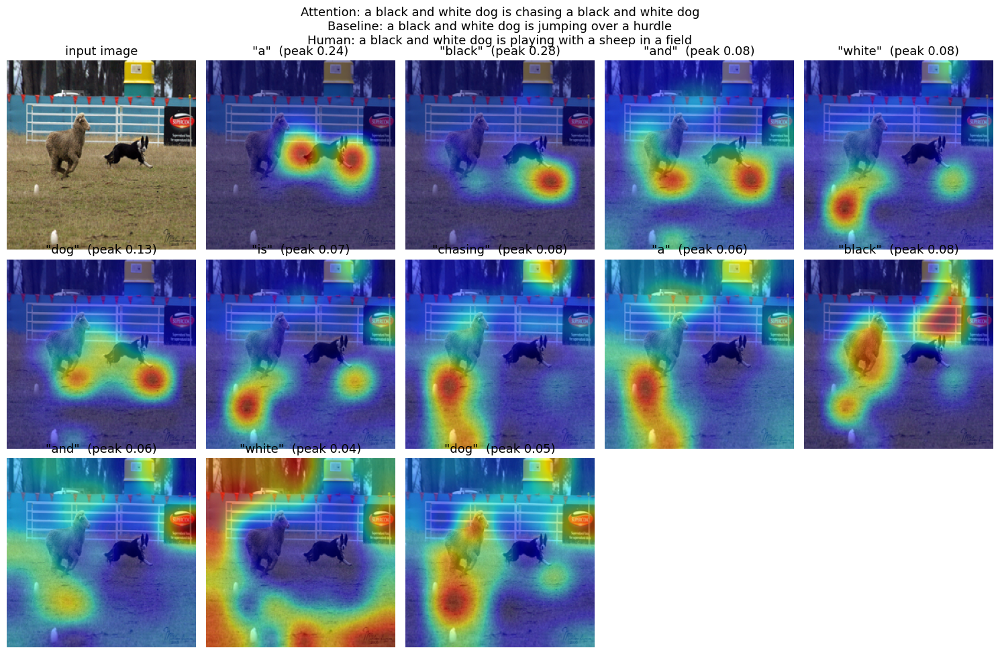

In [ ]:
def load_224(im):
    return np.asarray(Image.open(os.path.join(IMG_DIR, im)).convert('RGB').resize((224, 224)))

def upsample(a):                                       # 49 weights -> 224×224 smooth map
    a = torch.as_tensor(a).float().view(1, 1, 7, 7)
    up = F.interpolate(a, size=(224, 224), mode='bicubic', align_corners=False)[0, 0].clamp(min=0)
    return (up / up.max()).cpu().numpy()

def plot_attention(im, cols=5, max_words=14, save=None):
    words, al = att_caps[im][:max_words], test_alphas[im][:max_words]
    img = load_224(im)
    rows = int(np.ceil((len(words) + 1) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.3 * rows))
    axes = np.array(axes).reshape(-1)
    axes[0].imshow(img); axes[0].set_title('input image', fontsize=13)
    for i, (w, a) in enumerate(zip(words, al), start=1):
        axes[i].imshow(img)
        axes[i].imshow(upsample(a), cmap='jet', alpha=0.5)
        axes[i].set_title(f'"{w}"  (peak {a.max():.2f})', fontsize=13)
    for ax in axes: ax.axis('off')
    fig.suptitle(f"Attention: {' '.join(att_caps[im])}\nBaseline: {' '.join(base_caps[im])}"
                 f"\nHuman: {' '.join(img2refs[im][0])}", fontsize=13)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=300, bbox_inches='tight')
    plt.show()

plot_attention(test_imgs[0])

=== Attention wins ===
3066338314_2c3fb731d1.jpg


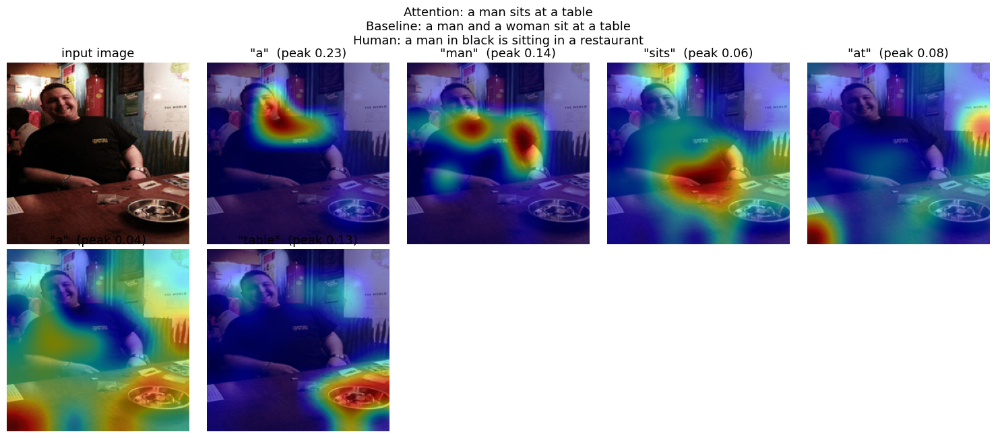

2735558076_0d7bbc18fc.jpg


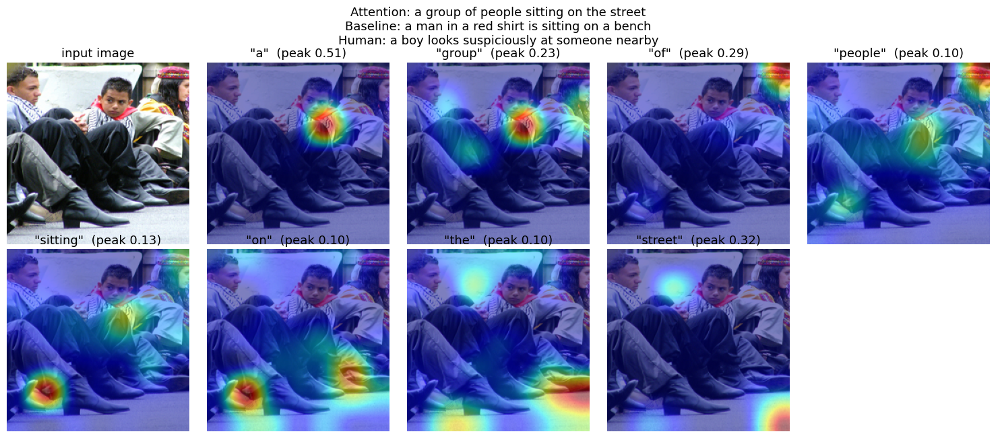

2616508003_fa5ca5780d.jpg


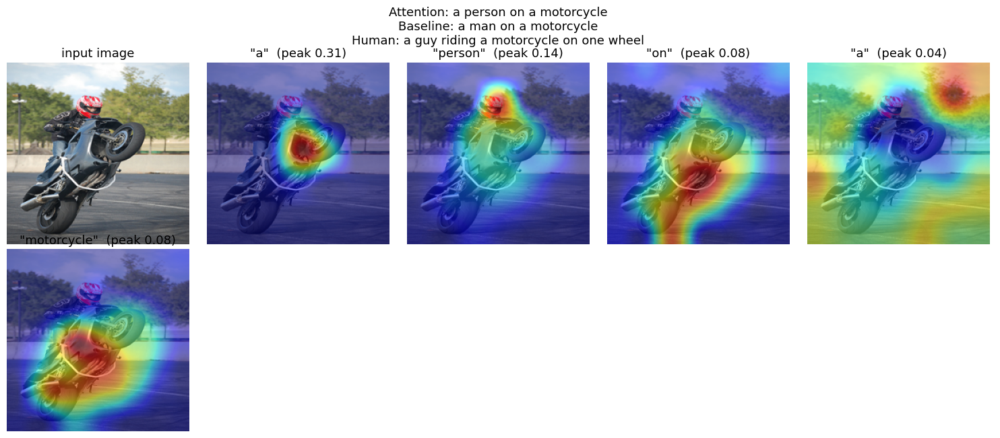

3446586125_cafa0bfd67.jpg


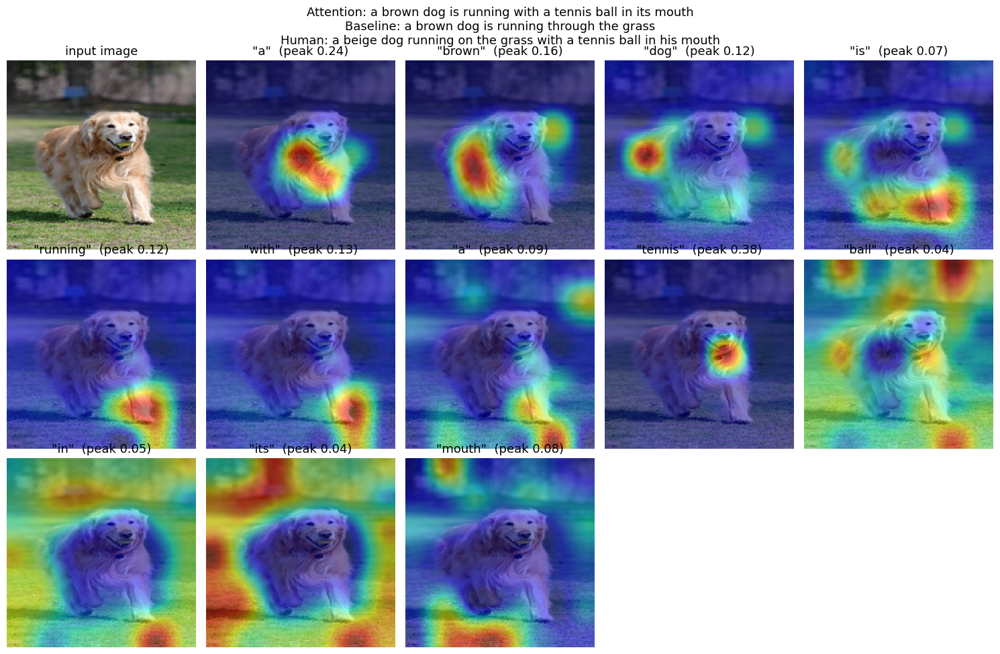

=== Attention losses ===
526661994_21838fc72c.jpg


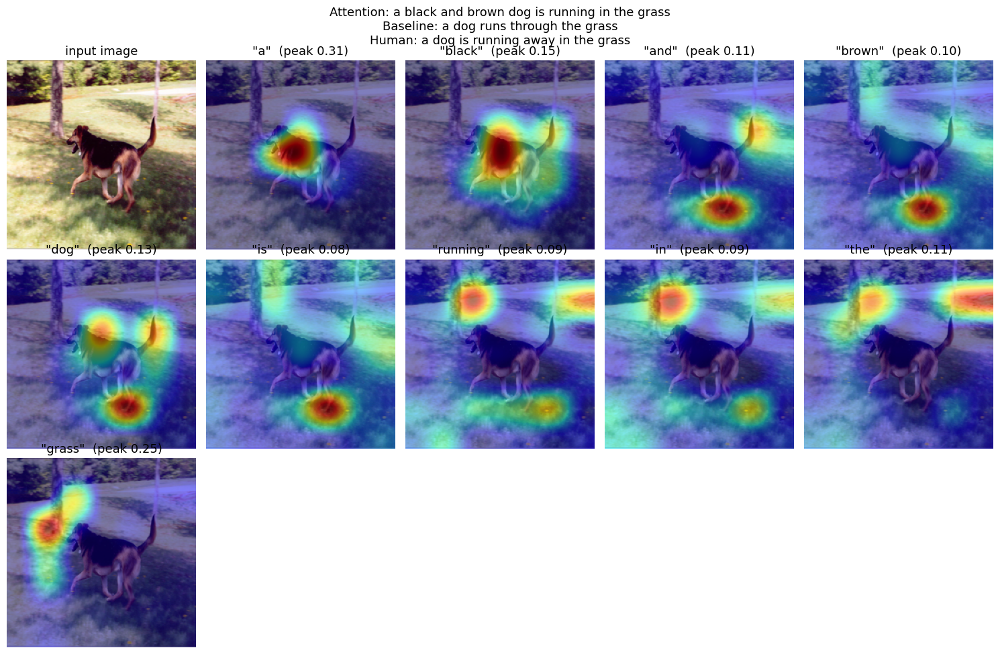

3210457502_c6030ce567.jpg


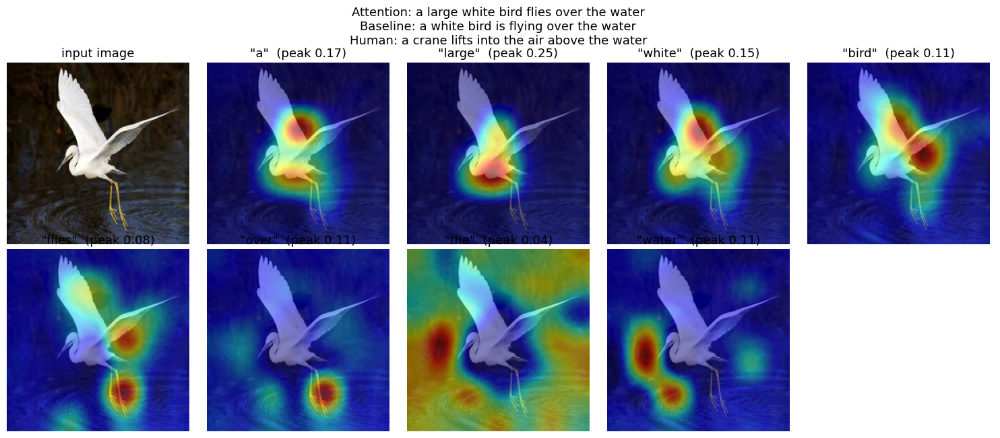

2326730558_75c20e5033.jpg


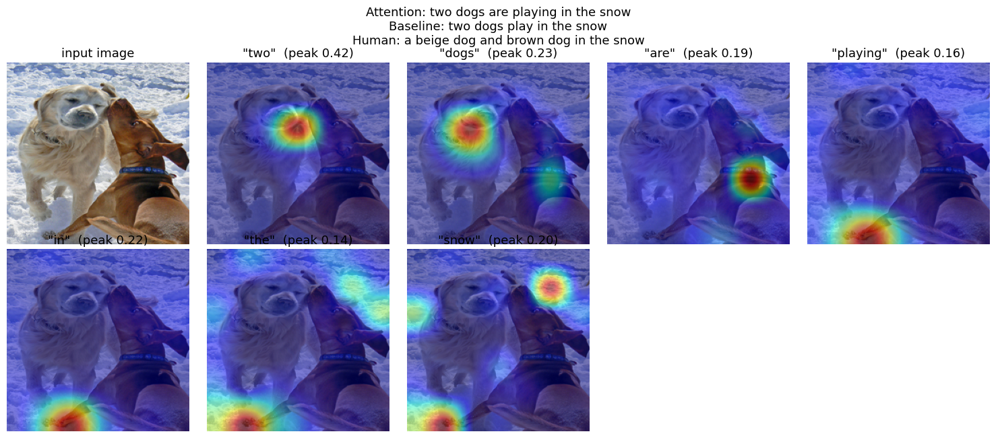

=== Random (an honest sample) ===
2300229745_af7a20c959.jpg


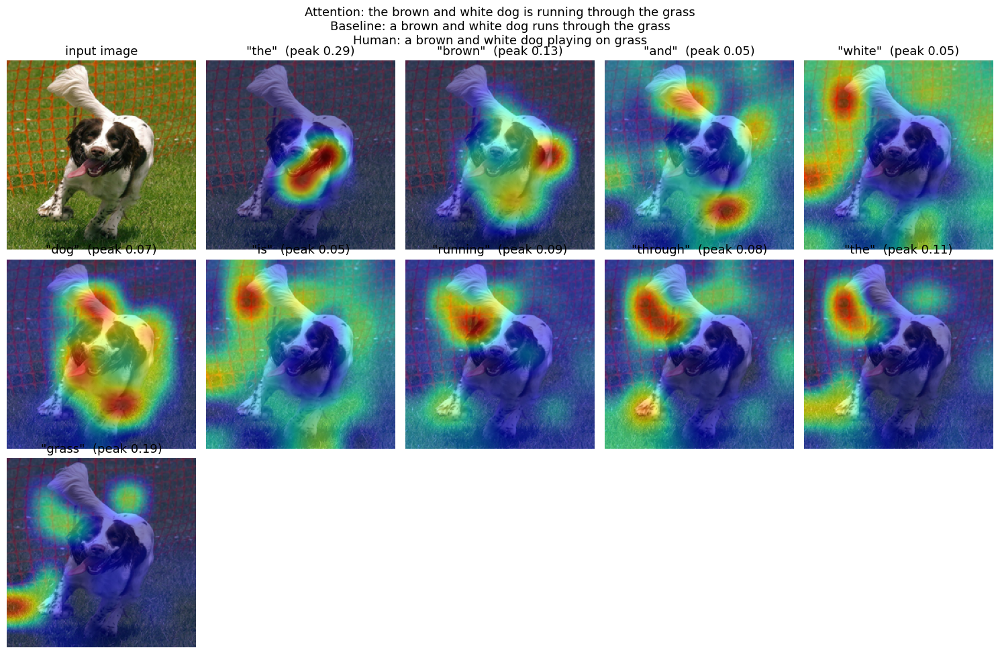

3457364788_3514a52091.jpg


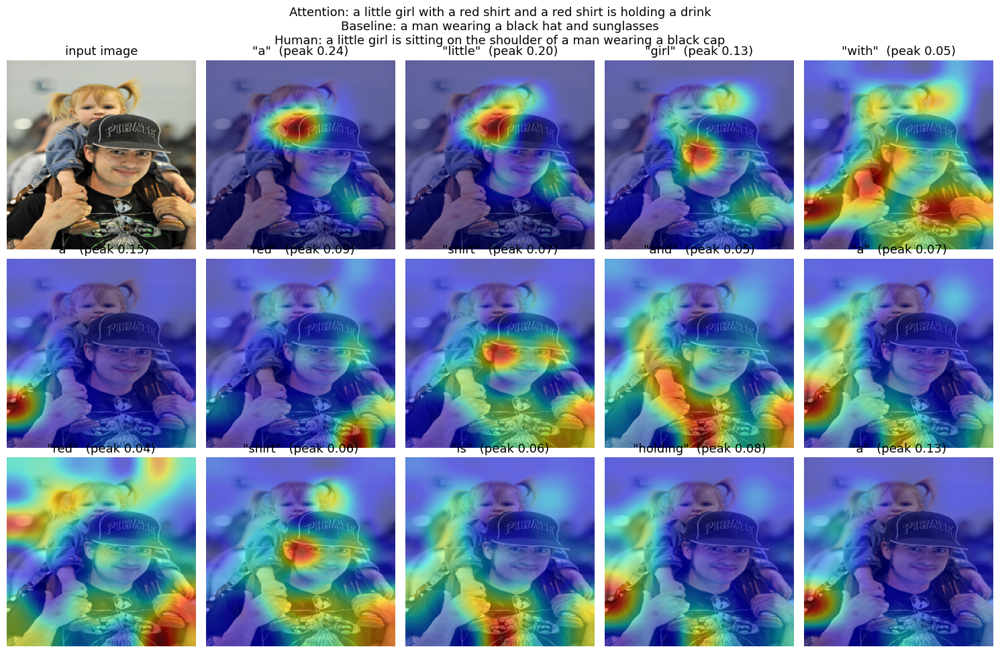

3204712107_5a06a81002.jpg


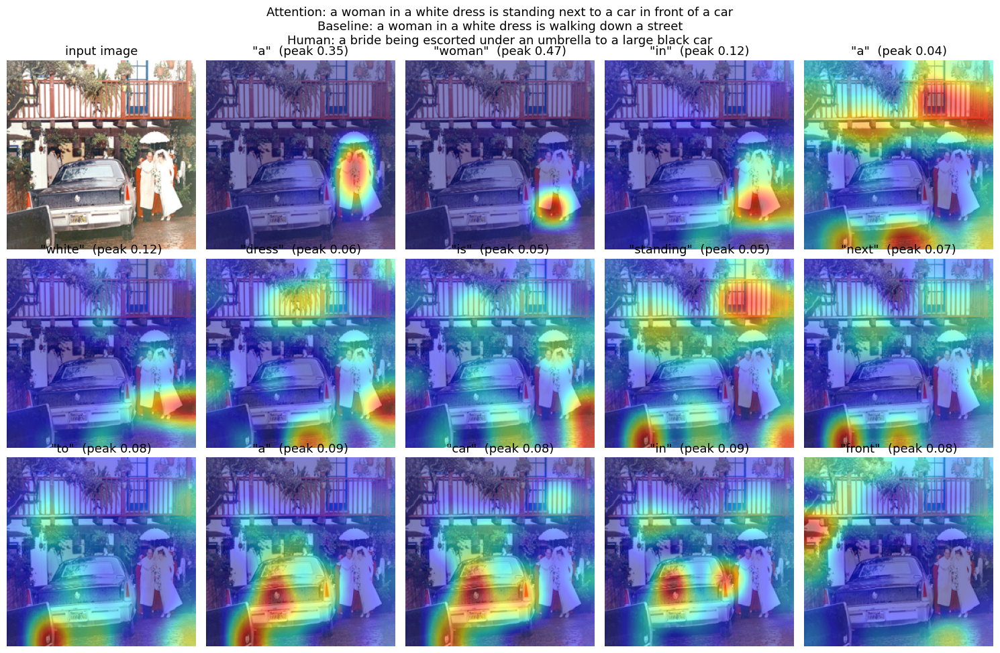

In [ ]:
wins   = per_img.nlargest(10, 'diff')['image'].tolist()     # attention beat baseline most
losses = per_img.nsmallest(10, 'diff')['image'].tolist()    # attention lost most

print("=== Attention wins ===")
for im in wins[:4]: print(im); plot_attention(im)
print("=== Attention losses ===")
for im in losses[:3]: print(im); plot_attention(im)
print("=== Random (an honest sample) ===")
for im in random.Random(0).sample(test_imgs, 3): print(im); plot_attention(im)

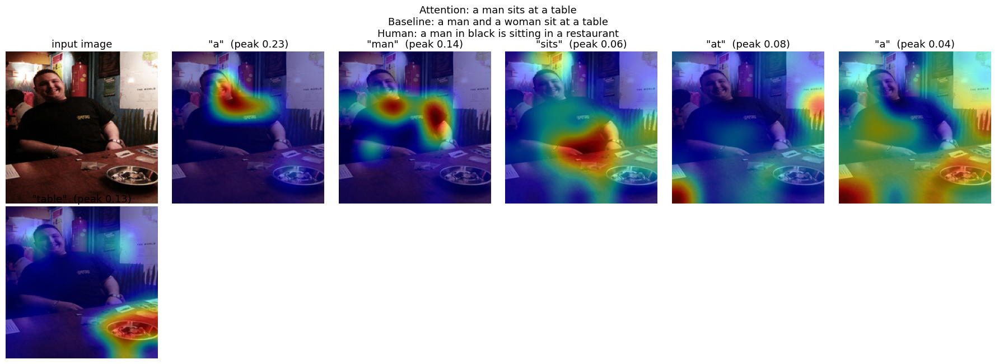

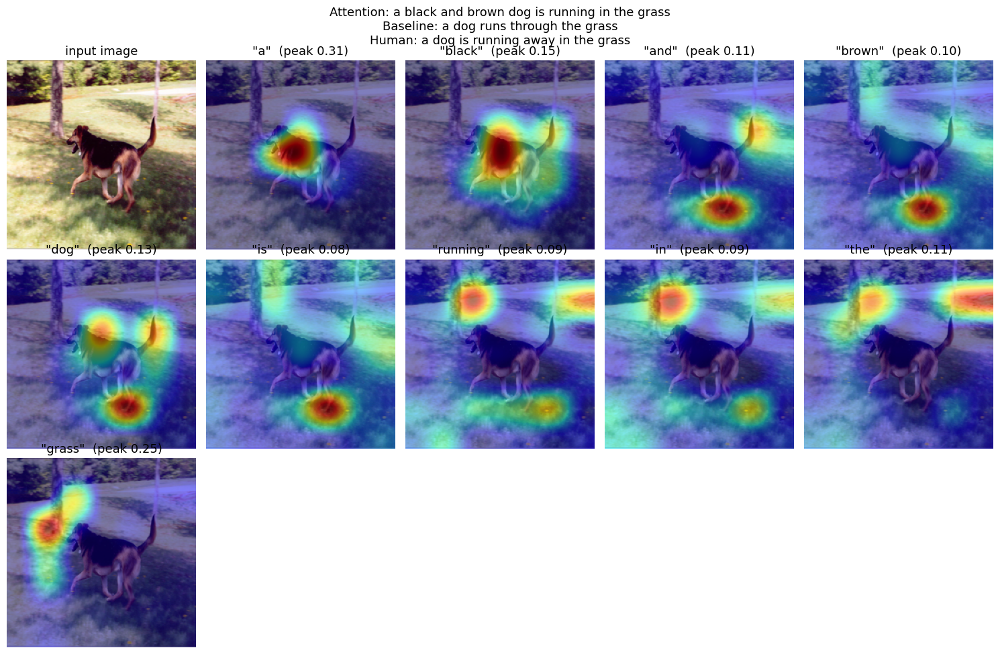

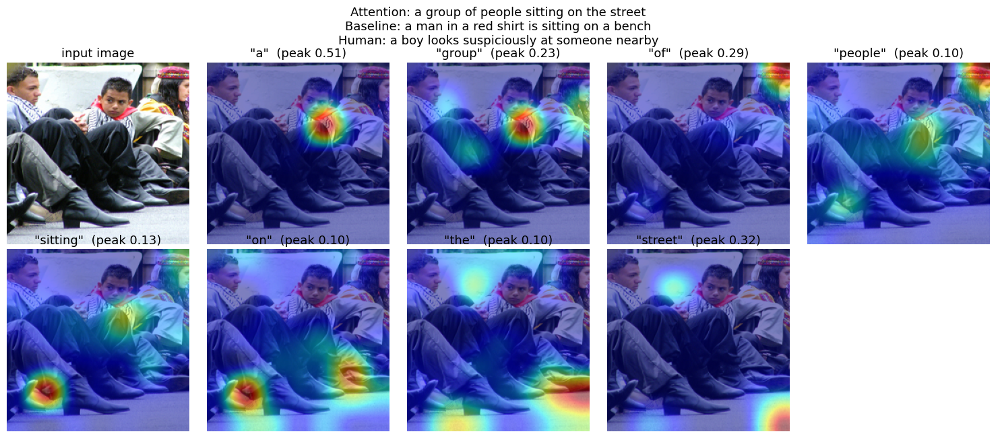

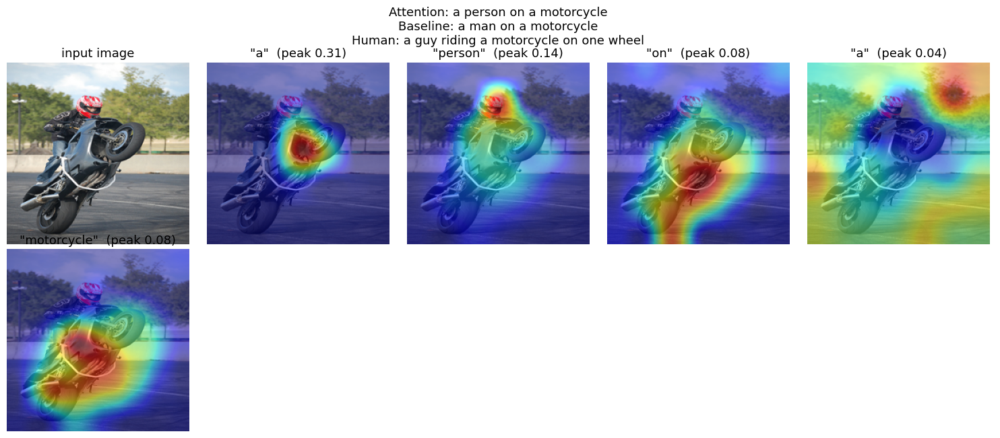

In [ ]:
GOOD = wins[0]        # ← replace with the file name of your clearest example, e.g. '1234567_abcdef.jpg'
FAIL = losses[0]      # ← replace with an instructive failure

plot_attention(GOOD, cols=6, max_words=11, save=f'{PROJECT_DIR}/fig_result2.png')     # the poster picks this up
plot_attention(FAIL, cols=5, save=f'{PROJECT_DIR}/fig_attention_failure.png')
for i, im in enumerate(wins[1:3]):
    plot_attention(im, save=f'{PROJECT_DIR}/fig_attention_example{i+1}.png')        # extra report figures

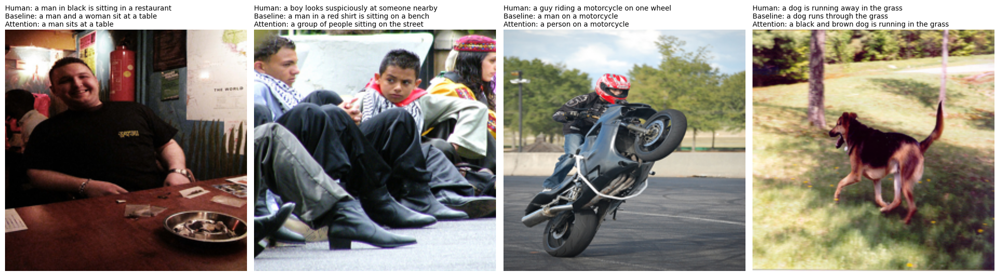

In [ ]:
show = [GOOD] + wins[1:3] + [FAIL]
fig, axes = plt.subplots(1, 4, figsize=(20, 6.5))
for ax, im in zip(axes, show):
    ax.imshow(load_224(im)); ax.axis('off')
    ax.set_title(f"Human: {' '.join(img2refs[im][0])}\n"
                 f"Baseline: {' '.join(base_caps[im])}\n"
                 f"Attention: {' '.join(att_caps[im])}", fontsize=10, loc='left', wrap=True)
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/fig_qualitative.png', dpi=300, bbox_inches='tight'); plt.show()

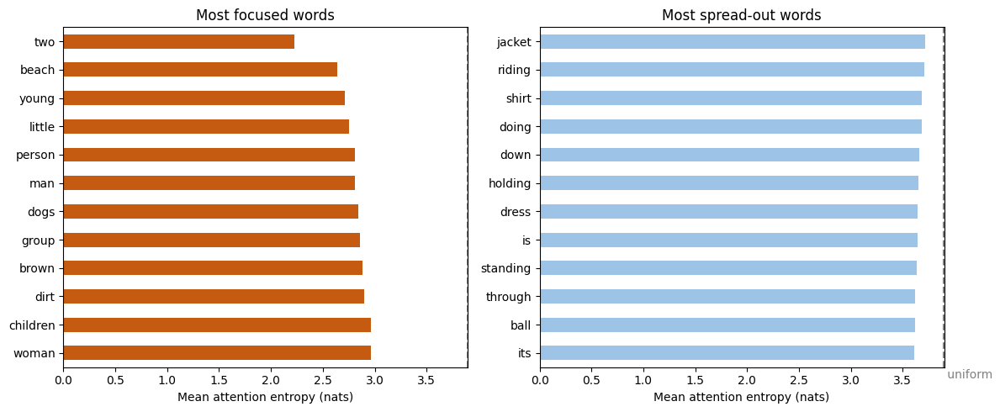

In [ ]:
from collections import defaultdict
ent_by_word = defaultdict(list)
for im in test_imgs:
    for w, a in zip(att_caps[im], test_alphas[im]):
        a = a.float().clamp_min(1e-9)
        ent_by_word[w].append(-(a * a.log()).sum().item())

ent = pd.Series({w: np.mean(v) for w, v in ent_by_word.items() if len(v) >= 20}).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
ent.head(12)[::-1].plot.barh(ax=ax[0], color='#C55A11'); ax[0].set_title('Most focused words')
ent.tail(12).plot.barh(ax=ax[1], color='#9DC3E6');       ax[1].set_title('Most spread-out words')
for a_ in ax:
    a_.axvline(np.log(49), ls='--', color='grey'); a_.set_xlabel('Mean attention entropy (nats)')
ax[1].text(np.log(49), -0.9, ' uniform', color='grey')
plt.tight_layout(); plt.savefig(f'{PROJECT_DIR}/fig_word_focus.png', dpi=300); plt.show()